<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/WeeklyModules/Week11/Week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
base_url = "https://raw.githubusercontent.com/wujh03/MSSP6070/main/data/"

In [3]:
population = pd.read_csv(
    base_url + "CA_Legislative_Districts.csv",
    dtype={"DISTRICT": str}
)

In [4]:
districts = gpd.read_file(
    base_url + "california-congressional-districts.geojson"
)

In [5]:
print("Population:", population.shape)

Population: (52, 25)


In [6]:
print("Districts:", districts.shape)

Districts: (53, 4)


In [7]:
display(population.head())

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,01,1,MTCAP,760066,549203,77031,10923,...,1|0,0.7226,0.1403,0.0199,0.0475,0.7507,1|0%,1,2.633906e+06,1.222952e+11
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.6621,0.1335,0.0523,0.1713,0.6220,10|0%,10,3.582890e+05,2.336909e+09
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.7479,0.1076,0.0596,0.3160,0.5006,11|0%,11,2.111932e+05,9.404054e+08
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.6723,0.1449,0.1994,0.2139,0.4169,12|-0%,12,1.246786e+05,5.869476e+08
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.5176,0.5024,0.0408,0.0621,0.3708,13|-0%,13,1.186868e+06,2.578115e+10


In [8]:
display(districts.head())

,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


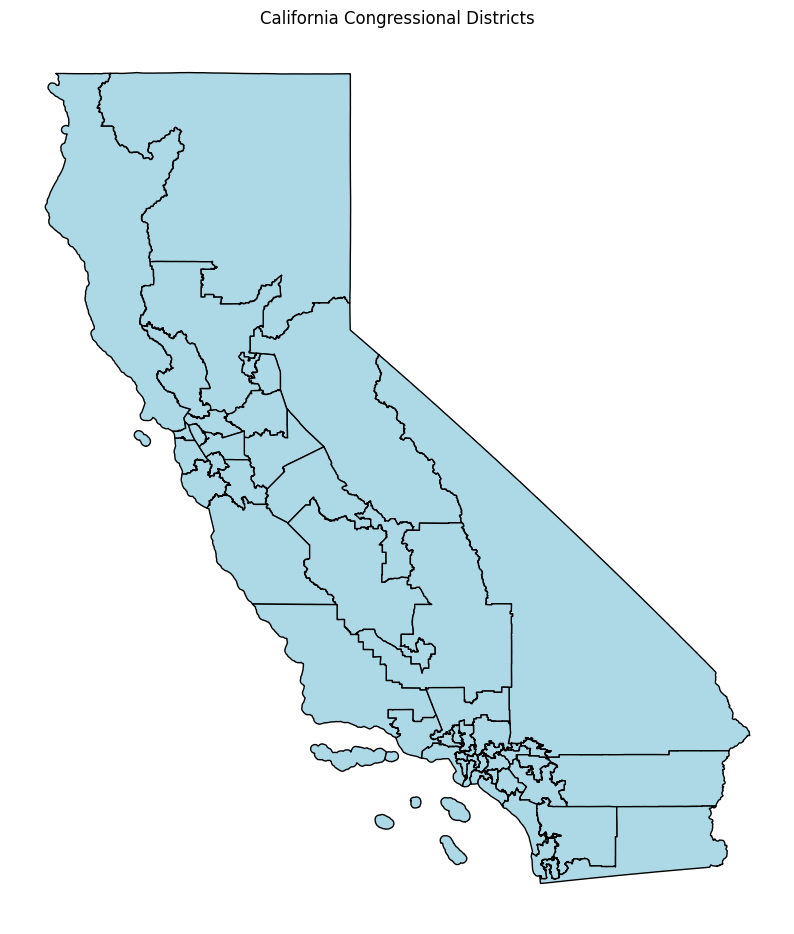

In [9]:
districts.plot(
    figsize=(10, 12),
    edgecolor="black",
    color="lightblue"
)
plt.title("California Congressional Districts")
plt.axis("off")
plt.show()

In [10]:

# Download the 52-district map
url = "https://www2.census.gov/geo/tiger/TIGER2022/CD/tl_2022_06_cd118.zip"

import requests

response = requests.get(url)
response.raise_for_status()

with open("ca_districts_52.zip", "wb") as f:
    f.write(response.content)

# Read the new map
new_districts = gpd.read_file("ca_districts_52.zip")

print(new_districts.shape)
print(new_districts.columns.tolist())
display(new_districts.head())


(52, 13)
['STATEFP20', 'GEOID20', 'CD118FP', 'NAMELSAD20', 'LSAD20', 'CDSESSN', 'MTFCC20', 'FUNCSTAT20', 'ALAND20', 'AWATER20', 'INTPTLAT20', 'INTPTLON20', 'geometry']


,STATEFP20,GEOID20,CD118FP,NAMELSAD20,LSAD20,CDSESSN,MTFCC20,FUNCSTAT20,ALAND20,AWATER20,INTPTLAT20,INTPTLON20,geometry
0,06,0601,01,Congressional District 1,C2,118,G5200,N,68358546344,1696265649,+40.7590582,-121.7085861,"POLYGON ((-123.71917 41.59561, -123.719 41.596..."
1,06,0602,02,Congressional District 2,C2,118,G5200,N,33770386578,4120164863,+40.0715357,-123.4644363,"POLYGON ((-124.482 40.44032, -124.47916 40.452..."
2,06,0603,03,Congressional District 3,C2,118,G5200,N,56116634345,988897803,+37.8264603,-118.8597634,"POLYGON ((-121.5949 39.19778, -121.59426 39.19..."
3,06,0607,07,Congressional District 7,C2,118,G5200,N,1762367953,68768946,+38.3615998,-121.3821071,"POLYGON ((-121.86254 38.06795, -121.86229 38.0..."
4,06,0604,04,Congressional District 4,C2,118,G5200,N,9790216355,380757598,+38.7356434,-122.3312293,"POLYGON ((-123.09422 39.08895, -123.09421 39.0..."


In [11]:
# Select the columns we need
pop = population[["DISTRICT", "POPULATION"]].copy()

# Match district ID formats
pop["DISTRICT"] = pop["DISTRICT"].astype(str).str.zfill(2)

new_districts["DISTRICT"] = (
    new_districts["CD118FP"].astype(str).str.zfill(2)
)

# Merge population with map boundaries
merged = new_districts.merge(
    pop,
    on="DISTRICT",
    how="left",
    validate="one_to_one"
)

# Check the result
print("Total districts:", len(merged))
print("Missing population:", merged["POPULATION"].isna().sum())

display(merged[["DISTRICT", "POPULATION"]].head())


Total districts: 52
Missing population: 0


,DISTRICT,POPULATION
0,01,760066
1,02,760067
2,03,760065
3,07,760066
4,04,760065


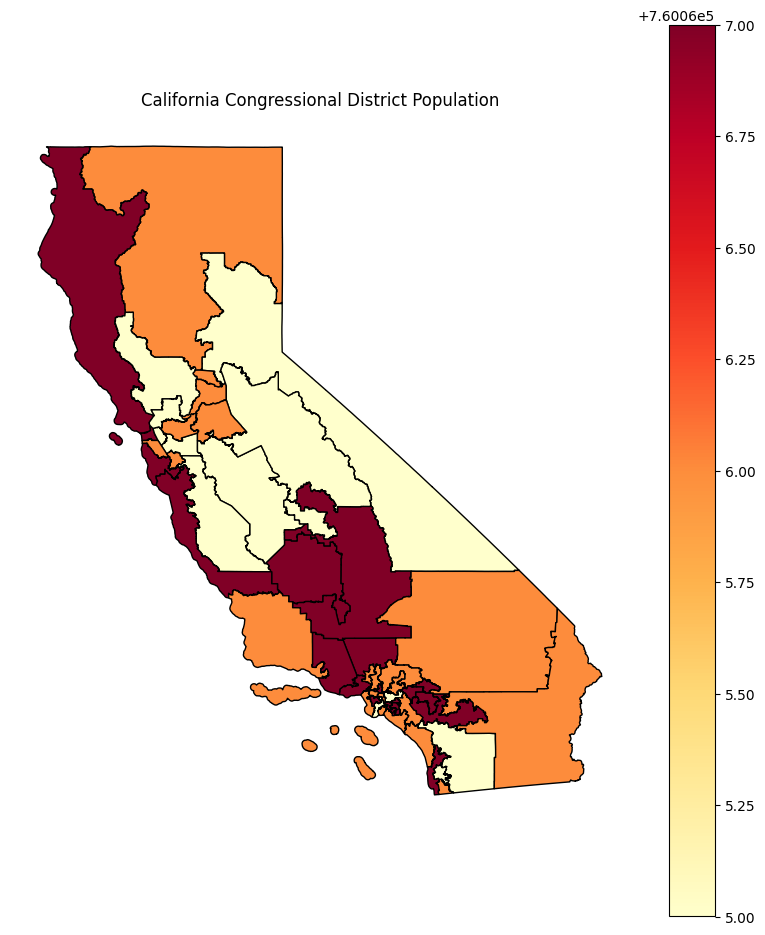

In [12]:
# Draw population heatmap
merged.plot(
    column="POPULATION",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    figsize=(10, 12)
)

plt.title("California Congressional District Population")
plt.axis("off")
plt.show()


In [13]:
# Convert the map to California's equal-area projection
density_map = merged.to_crs(epsg=3310).copy()

# Calculate district area in square kilometers
density_map["area_km2"] = density_map.geometry.area / 1000000

# Calculate population density
density_map["density"] = (
    density_map["POPULATION"] / density_map["area_km2"]
)

# Check the results
display(density_map[[
    "DISTRICT", "POPULATION", "area_km2", "density"
]].head())


,DISTRICT,POPULATION,area_km2,density
0,01,760066,70054.818368,10.849589
1,02,760067,37890.555010,20.059537
2,03,760065,57105.536459,13.309830
3,07,760066,1831.137055,415.078706
4,04,760065,10170.974711,74.728826


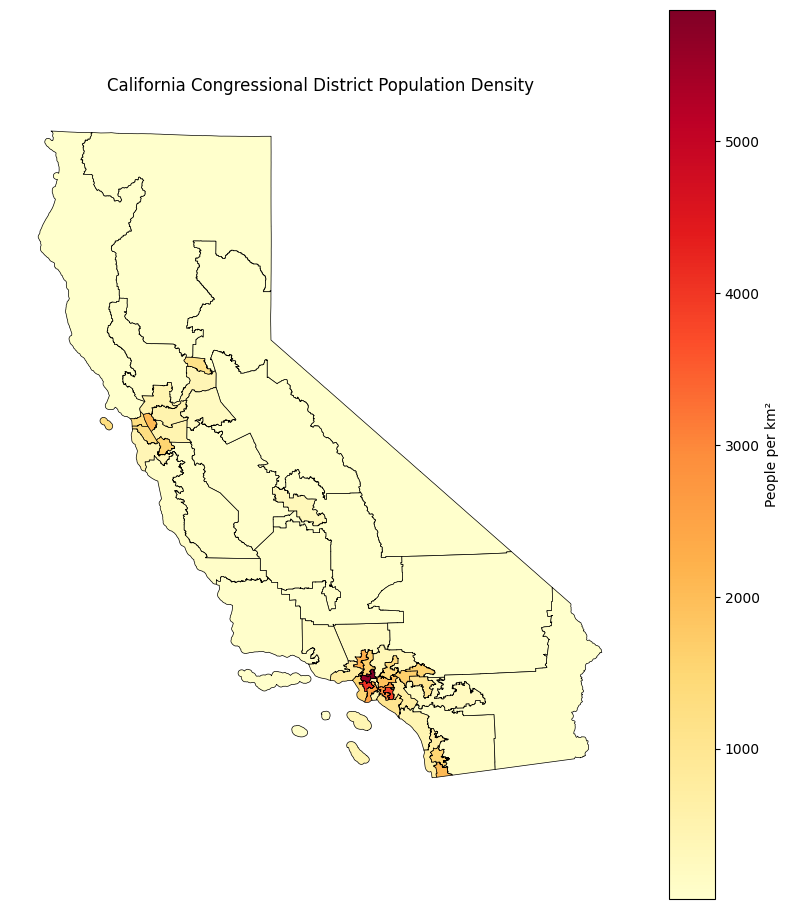

In [14]:
# Create population density heatmap
fig, ax = plt.subplots(figsize=(10, 12))

density_map.plot(
    column="density",
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "People per km²"},
    edgecolor="black",
    linewidth=0.5,
    ax=ax
)

plt.title("California Congressional District Population Density")
plt.axis("off")

# Save the figure
plt.savefig("California_Population_Density.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [15]:
# Check the final dataset
print("Number of districts:", len(density_map))
print("Missing population:", density_map["POPULATION"].isna().sum())

print("Total population:", density_map["POPULATION"].sum())

print("Lowest density:", density_map["density"].min())
print("Highest density:", density_map["density"].max())

Number of districts: 52
Missing population: 0
Total population: 39523437
Lowest density: 10.849589189037175
Highest density: 5863.467845069452
